
# Lab: Data Cleaning and Reporting

## Objectives
Complete the missing code blocks to **continue** cleaning the `customers` dataset and log your actions.


In [40]:

# Install necessary libraries
%pip install pandas numpy matplotlib seaborn


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [41]:

import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# Database connection
db_name = 'customers.db'
conn = sqlite3.connect(db_name)

# Helper function to log cleaning steps (with Duplicate Check)
def log_cleaning_step(step_num, action, col, details, reason, rows_affected):
    cursor = conn.cursor()
    
    # Check if this step already exists
    cursor.execute("SELECT count(*) FROM cleaning_logs WHERE step_number = ?", (step_num,))
    exists = cursor.fetchone()[0]
    
    if exists > 0:
        # Option A: Update the existing log (if you re-run with different logic)
        cursor.execute('''
            UPDATE cleaning_logs 
            SET action_type = ?, column_affected = ?, details = ?, reason = ?, rows_affected = ?, timestamp = CURRENT_TIMESTAMP
            WHERE step_number = ?
        ''', (action, col, details, reason, rows_affected, step_num))
        print(f"Log updated: Step {step_num} - {action} on {col}")
    else:
        # Option B: Insert new log
        cursor.execute('''
            INSERT INTO cleaning_logs (step_number, action_type, column_affected, details, reason, rows_affected)
            VALUES (?, ?, ?, ?, ?, ?)
        ''', (step_num, action, col, details, reason, rows_affected))
        print(f"Log added: Step {step_num} - {action} on {col}")
        
    conn.commit()


In [42]:

# Read data from 'partially_cleaned_customers' table into a DataFrame 'df'.
df = pd.read_sql_query(
   "SELECT * FROM partially_cleaned_customers", 
   conn, 
   parse_dates=['join_date']
)
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   cust_id    200 non-null    object        
 1   full_name  200 non-null    object        
 2   email      175 non-null    object        
 3   age        192 non-null    float64       
 4   income     180 non-null    float64       
 5   join_date  195 non-null    datetime64[ns]
 6   city       153 non-null    object        
dtypes: datetime64[ns](1), float64(2), object(4)
memory usage: 11.1+ KB


### Important Note: Critical Order of Operations

The order in which you clean data matters significantly. The dependency chain is as follows:

1.  **Step 1: Accuracy/Validity**: Fix impossible values (e.g., Age 200, Salary -5000) **before** calculating any statistics.
    *   *Why?* If you don't, your Mean/Median will be wrong.
2.  **Step 2: Completeness (Imputation)**: Fill missing values using the **clean** statistics from Step 1.
    *   *Why?* If you imputed before fixing accuracy, you would fill gaps with garbage values based on incorrect statistics.
3.  **Step 3: Outliers/Consistency**: Handle statistical outliers on valid data.

> **Example**: If you calculate the Mean Age including a value of 200, your Mean will be inflated. If you then use that Mean to fill missing ages, you propagate the error to new rows.


## Dimension: Accuracy

**Accuracy** means the data reflects reality. 
We check for values that are "technically valid" (numbers/dates) but **impossible** in the real world.

**Checks:**
1.  **Age**: Cannot be less than 10 or unreasonably high (e.g., > 120).
2.  **Join Date**: Cannot be in the future 


In [43]:

# Audit: Visualize constraints
# TODO: print age min and max 
print(df['age'].max())
print(df['age'].min())

# TODO: Filter and print rows where 'join_date' is greater than the current date (future dates).
unrealistic_date = df[df['join_date'] > datetime.today()]
print(unrealistic_date)



250.0
1.0
    cust_id full_name                email   age    income  join_date  \
24    C1025   User 25   user25@example.com  15.0   7429.87 2026-07-25   
49    C1050   User 50   user50@example.com  12.0       NaN 2026-04-29   
74    C1075   User 75   user75@example.com  17.0  47443.09 2026-08-17   
99    C1100  User 100  user100@example.com  12.0       NaN 2026-11-14   
124   C1125  User 125  user125@example.com  41.0  52285.98 2026-10-06   
149   C1150  User 150  user150@example.com  21.0       NaN 2026-07-07   
174   C1175  User 175  user175@example.com   7.0  29968.36 2026-08-15   
199   C1200  User 200                 None  11.0       NaN 2026-10-06   

         city  
24       None  
49     london  
74   new york  
99   new york  
124    london  
149      None  
174     cairo  
199     cairo  


In [ ]:
age_before = df['age'].copy()
join_date_before = df['join_date'].copy()
# 1. Handle Impossible Ages (<10 or >120)
# We treat these as ERRORS. 
# Option A: Drop rows. Option B: Set to NaN. Option C: Cap.
# Lecture 4 suggests capping or nullifying based on context. Let's Cap for this lab.

rows_affected_age = len(df[(df['age'] > 120) | (df['age'] < 10)])
# TODO: Cap 'age' at 120 (max) and 10 (min). Replace values outside this range with the boundary values. 
df['age'] = df['age'].clip(lower=10, upper=120)
print(df['age'].max())
print(df['age'].min())
# 2. Handle Future Dates
current_date = pd.Timestamp.now().normalize() 
# TODO: get/mask dates > current_date and uncomment needed lines
future_mask = df['join_date'] > datetime.today()
rows_affected_date = future_mask.sum()
print(f"Fixing {rows_affected_date} future dates.")

# TODO: Replace the dates in df that violated the check with 'current_date' 
df.loc[future_mask, 'join_date'] = current_date



age_changed = (df['age'] != age_before)
join_date_changed = (df['join_date'] != join_date_before)
rows_affected = (age_changed | join_date_changed).sum()
# TODO: write reason for this cleaning step
reason = "age entries more out of ranges (10, 120), unrealistic join_date (future)"
log_cleaning_step(step_num=5, action='Accuracy Correction', col='age, join_date', details='Capped Age (10-120), Fixed Future Dates to Today', reason=reason, rows_affected=int(rows_affected))

120.0
10.0
Fixing 8 future dates.
Log updated: Step 5 - Accuracy Correction on age, join_date



## Dimension: Completeness (Missing Data)


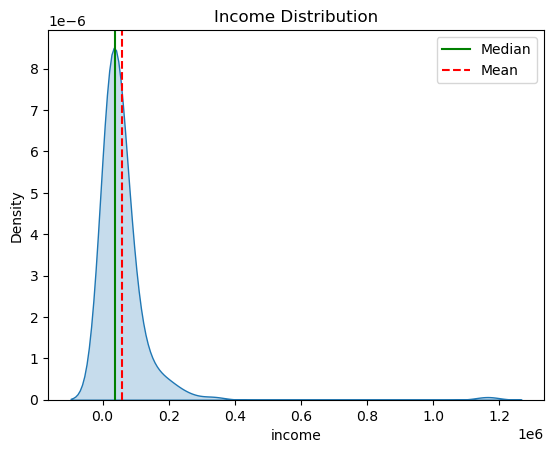

In [45]:
# TODO: run this plot after finishing above requirments
sns.kdeplot(df['income'].dropna(), fill=True)

plt.title('Income Distribution')
plt.axvline(df['income'].median(), color='g', linestyle='-', label='Median')
plt.axvline(df['income'].mean(), color='r', linestyle='--', label='Mean')
plt.legend()
plt.show()

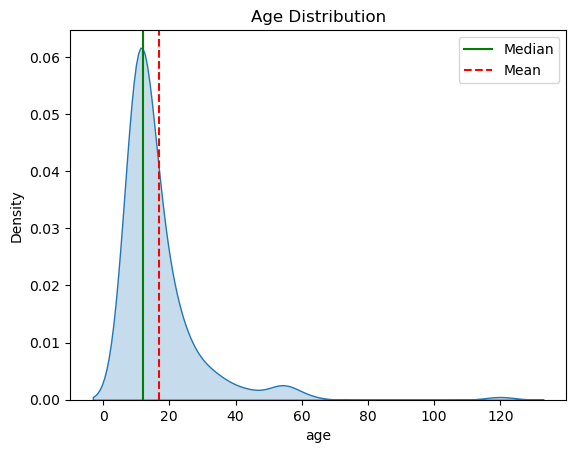

In [46]:
# TODO: run this plot after finishing above requirments
sns.kdeplot(df['age'].dropna(), fill=True)

plt.title('Age Distribution')
plt.axvline(df['age'].median(), color='g', linestyle='-', label='Median')
plt.axvline(df['age'].mean(), color='r', linestyle='--', label='Mean')
plt.legend()
plt.show()

In [47]:
# Calculate affected rows BEFORE filling
# We check which rows have at least one null value in the columns we are about to clean
cols_to_clean = ['income', 'age', 'city', 'email', 'join_date']
rows_affected_imputation = df[cols_to_clean].isnull().any(axis=1).sum()

# --- QUESTION: Observe the KDE plots above.
# 1. Are the distributions for 'age' and 'income' symmetrical or skewed?
# right skewed

# 2. Based on the answer, which measure of central tendency (Mean or Median) would you use?
# median

# TODO: for each of the below use the suitable way e.g.(mean/median/mode/constant/unknown) for handling missing values according to the column's distribtion

# 1. Income (Numerical) - TODO: fill nan with suitable value
median_income = df['income'].median()
df['income'] = df['income'].fillna(median_income)

# 2. Age (Numerical) - TODO: fill nan with suitable value
median_age = df['age'].median()
df['age'] = df['age'].fillna(median_age) 

# 3. City (Categorical) - TODO: fill nan with suitable value
city_mode = df['city'].mode()[0]
# print(city_mode[0])
print(df['city'].value_counts())
df['city'] = df['city'].fillna(city_mode)

# 4. Email (Categorical) - TODO: fill nan with suitable value
df['email'] = df['email'].fillna('UNKOWN')

# 5. Date - TODO: fill nan with suitable value. Hint: use current_date
df['join_date'] = df['join_date'].fillna(current_date)

# TODO: write reason for each handling you did
reason = "age and incrome were right skewed, used the most frequent city, emails cannot be guessed, setting unkown join_date with current date"
log_cleaning_step(step_num=6, action='Imputation', col='income, age, city, email, join_date', details='Filled Nulls', reason=reason, rows_affected=int(rows_affected_imputation))
print(rows_affected_imputation)
# Test
print("Remaining Nulls:", df.isnull().sum().sum())
assert df.isnull().sum().sum() == 0


city
new york    56
london      42
cairo       36
paris       19
Name: count, dtype: int64
Log updated: Step 6 - Imputation on income, age, city, email, join_date
71
Remaining Nulls: 0



## Outliers (Extreme but Valid)
**Outliers** are valid numbers that are just very high or low.
Unlike "Accuracy" issues (Age 250), an Income of $2M *could* be real, but it distorts the mean.

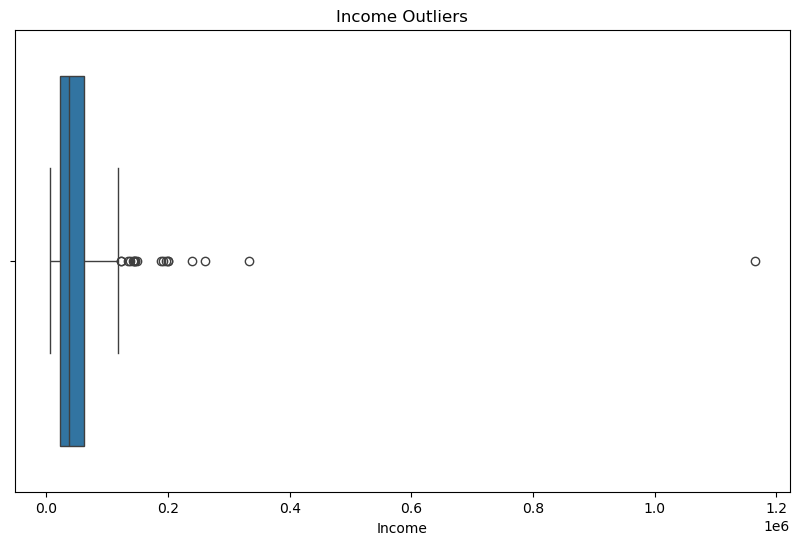

In [48]:
# TODO: run this plot after finishing above requirments
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['income'])
plt.title('Income Outliers')
plt.xlabel('Income')
plt.show()

In [49]:
# Handle Income Outliers using IQR
# TODO: Calculate Q1 and Q3. Calculate IQR and upper_bound.

Q1 = df['income'].quantile(0.25)


Q3 = df['income'].quantile(0.75)


IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

# TODO: select rows whose income > upper_bound and uncomment needed lines
rows_affected_income = len(df[df['income'] > upper_bound])
print(f"Capping {rows_affected_income} income outliers at {upper_bound}")

# TODO: cap income > upper_bound to upper_bound
df['income'] = df['income'].clip(upper=upper_bound)

# TODO: write reason 
reason = "extreme income, could affect the mean"
log_cleaning_step(step_num=7, action='Outlier Handling', col='income', details='Capped Income (IQR)', reason=reason, rows_affected=int(rows_affected_income))


Capping 18 income outliers at 121515.725
Log updated: Step 7 - Outlier Handling on income


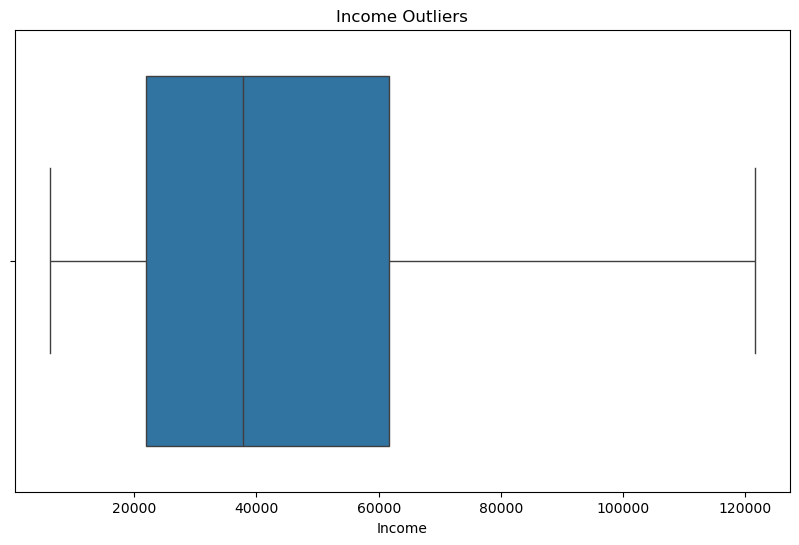

In [50]:
# TODO: run this plot after finishing above requirments
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['income'])
plt.title('Income Outliers')
plt.xlabel('Income')
plt.show()

In [51]:
logs = pd.read_sql_query("SELECT * FROM cleaning_logs ORDER BY step_number", conn)
logs

,log_id,step_number,action_type,column_affected,details,reason,rows_affected,timestamp
0,1,1,Removal,All,Removed duplicate records,Exact duplicates provide no new information an...,10,2026-03-07 12:02:07
1,2,2,Type Casting,"age, income","Converted to numeric, invalid values set to NaN",Calculations require numeric types. 'Coerce' h...,200,2026-03-07 12:02:08
2,3,3,Type Casting,join_date,"Converted to datetime, invalid values set to NaN",Dates need datetime format for time-based log...,200,2026-03-07 12:02:08
3,4,4,Standardization,"city, email","Lowercased, stripped whitespace, mapped NY->ne...",Inconsistent casing (New York vs new york) and...,130,2026-03-07 12:02:08
4,11,5,Accuracy Correction,"age, join_date","Capped Age (10-120), Fixed Future Dates to Today","age entries more out of ranges (10, 120), unre...",88,2026-03-12 07:59:50
5,12,6,Imputation,"income, age, city, email, join_date",Filled Nulls,"age and incrome were right skewed, used the mo...",71,2026-03-12 07:59:52
6,13,7,Outlier Handling,income,Capped Income (IQR),"extreme income, could affect the mean",18,2026-03-12 07:59:52
